In [9]:
# importation des packages
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import LSTM

In [3]:
# ouvrir data
df = pd.read_csv('/content/AirPassengers.csv')
df.head()

,Month,#Passengers
0,1949-01,112
1,1949-02,118
2,1949-03,132
3,1949-04,129
4,1949-05,121


In [7]:
data = df[['#Passengers']].values
print(data.shape)

(144, 1)


In [12]:
# preparation du data
sc = MinMaxScaler(feature_range=(0,1))
data_scaled = sc.fit_transform(data)
data_scaled

array([[0.01544402],
       [0.02702703],
       [0.05405405],
       [0.04826255],
       [0.03281853],
       [0.05984556],
       [0.08494208],
       [0.08494208],
       [0.06177606],
       [0.02895753],
       [0.        ],
       [0.02702703],
       [0.02123552],
       [0.04247104],
       [0.07142857],
       [0.05984556],
       [0.04054054],
       [0.08687259],
       [0.12741313],
       [0.12741313],
       [0.1042471 ],
       [0.05598456],
       [0.01930502],
       [0.06949807],
       [0.07915058],
       [0.08880309],
       [0.14285714],
       [0.11389961],
       [0.13127413],
       [0.14285714],
       [0.18339768],
       [0.18339768],
       [0.15444015],
       [0.11196911],
       [0.08108108],
       [0.11969112],
       [0.12934363],
       [0.14671815],
       [0.17181467],
       [0.14864865],
       [0.15250965],
       [0.22007722],
       [0.24324324],
       [0.26640927],
       [0.2027027 ],
       [0.16795367],
       [0.13127413],
       [0.173

In [16]:
x_data = []
y_data = []
look_back = 1
for i in range(len(data_scaled)-1):
  x_data.append(data_scaled[i:(i+look_back),0])
  y_data.append(data_scaled[i+look_back,0])
x_data,y_data = np.array(x_data),np.array(y_data)


In [17]:
# reshaping
x_data = np.reshape(x_data,(x_data.shape[0],x_data.shape[1],1))
x_data.shape

(143, 1, 1)

In [18]:
 # split data into test and train
 train_size = int(len(x_data)*0.7)
 test_size = len(x_data)-train_size
 x_train = x_data[0:train_size,:]
 y_train = y_data[0:train_size]
 x_test = x_data[train_size:len(x_data),:]
 y_test = y_data[train_size:len(y_data)]

In [35]:
# construction de RNN
model = Sequential()
model.add(LSTM(units = 50,return_sequences=True,input_shape=(x_train.shape[1],1)))
model.add(LSTM(units = 50,return_sequences=True))
model.add(LSTM(units = 50))
#Ajoutons couche de sortie
model.add(Dense(units=1))
model.compile(loss='mean_squared_error',optimizer='adam')
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_9 (LSTM)                   │ (None, 1, 50)          │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_10 (LSTM)                  │ (None, 1, 50)          │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_11 (LSTM)                  │ (None, 50)             │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,851 (198.64 KB)

 Trainable params: 50,851 (198.64 KB)

 Non-trainable params: 0 (0.00 B)

In [36]:
# fiting model
model.fit(x_train,y_train,epochs=100,batch_size=32)

Epoch 1/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - loss: 0.0695
Epoch 2/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0633 
Epoch 3/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0571 
Epoch 4/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0502 
Epoch 5/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0436 
Epoch 6/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0364 
Epoch 7/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0298 
Epoch 8/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0241 
Epoch 9/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0193 
Epoch 10/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0168 
Epoch 11/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0165 
Epoch 12/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0172
Epoch 13/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0169 
Epoch 14/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0159 
Epoch 15/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0150 
Epoch 16/100
4/4 ━━━

In [37]:
# realisation des precisions
y_pred = model.predict(x_test)
y_pred

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 248ms/step


array([[0.49343187],
       [0.6368653 ],
       [0.7317815 ],
       [0.7362403 ],
       [0.597744  ],
       [0.47673666],
       [0.39081   ],
       [0.45394695],
       [0.4622115 ],
       [0.41708586],
       [0.5081213 ],
       [0.47881803],
       [0.5102259 ],
       [0.6653564 ],
       [0.79000735],
       [0.82157034],
       [0.597744  ],
       [0.50181663],
       [0.40088096],
       [0.45601067],
       [0.5039167 ],
       [0.46635348],
       [0.602071  ],
       [0.580487  ],
       [0.6324993 ],
       [0.7474029 ],
       [0.91921204],
       [0.9443149 ],
       [0.7273262 ],
       [0.60423654],
       [0.5081213 ],
       [0.59990686],
       [0.625959  ],
       [0.569744  ],
       [0.630318  ],
       [0.7228745 ],
       [0.7474029 ],
       [0.8896002 ],
       [1.0884689 ],
       [1.0518435 ],
       [0.8283506 ],
       [0.7228745 ],
       [0.5675994 ]], dtype=float32)

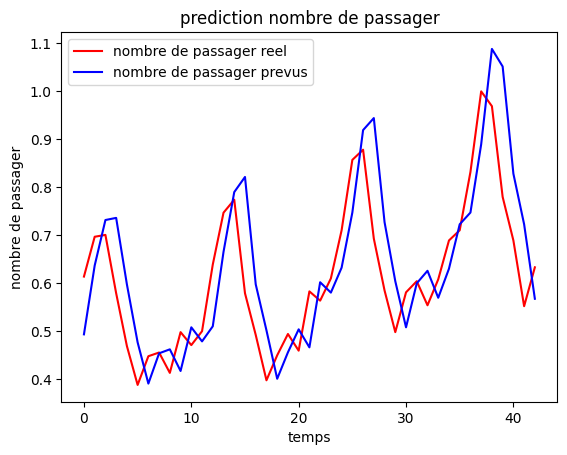

In [38]:
# visualiser les resultats
plt.plot(y_test,color='red',label='nombre de passager reel')
plt.plot(y_pred,color='blue',label='nombre de passager prevus')
plt.title('prediction nombre de passager')
plt.xlabel('temps')
plt.ylabel('nombre de passager')
plt.legend()
plt.show()